# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = pd.read_csv('House_Rent_Dataset.csv')

print(f'Розмір датасету: {df.shape[0]} рядків, {df.shape[1]} колонок')

Розмір датасету: 4746 рядків, 12 колонок


In [2]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


**Висновок.** У датасеті 4 746 оголошень і 12 колонок. Числових колонок 4: `BHK`, `Rent`, `Size`, `Bathroom`. Решта 8 — текстові (`object`). У кожній колонці 4 746 непорожніх значень, тобто пропусків немає. Дата `Posted On` збережена як текст.

## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [4]:
missing = pd.DataFrame({
    'Пропусків': df.isnull().sum(),
    'Відсоток, %': (df.isnull().mean() * 100).round(2),
})
missing

,Пропусків,"Відсоток, %"
Posted On,0,0.0
BHK,0,0.0
Rent,0,0.0
Size,0,0.0
Floor,0,0.0
Area Type,0,0.0
Area Locality,0,0.0
City,0,0.0
Furnishing Status,0,0.0
Tenant Preferred,0,0.0


In [5]:
df.describe().round(1)

,BHK,Rent,Size,Bathroom
count,4746.0,4746.0,4746.0,4746.0
mean,2.1,34993.5,967.5,2.0
std,0.8,78106.4,634.2,0.9
min,1.0,1200.0,10.0,1.0
25%,2.0,10000.0,550.0,1.0
50%,2.0,16000.0,850.0,2.0
75%,3.0,33000.0,1200.0,2.0
max,6.0,3500000.0,8000.0,10.0


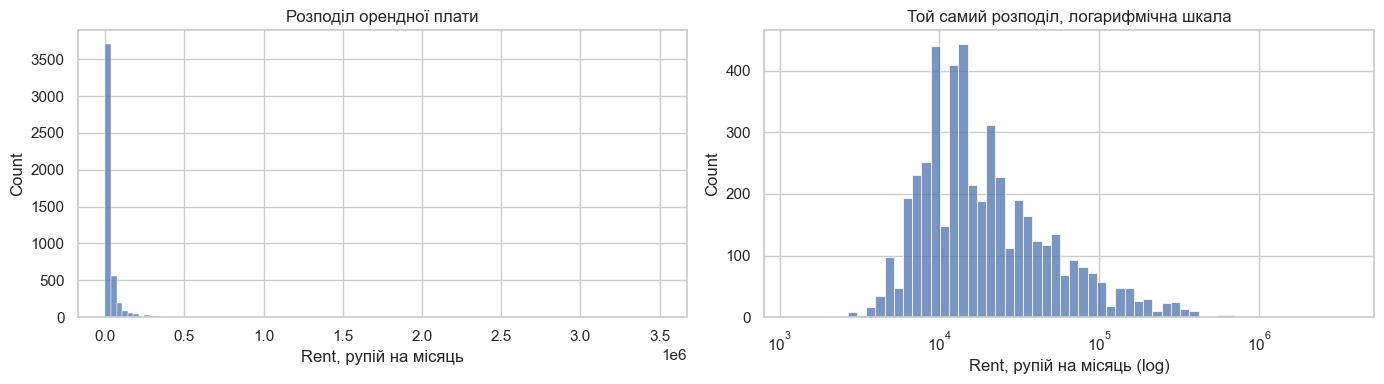

Медіана: 16,000, середнє: 34,993, асиметрія: 21.4


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['Rent'], bins=100, ax=axes[0])
axes[0].set_title('Розподіл орендної плати')
axes[0].set_xlabel('Rent, рупій на місяць')
sns.histplot(df['Rent'], bins=60, log_scale=True, ax=axes[1])
axes[1].set_title('Той самий розподіл, логарифмічна шкала')
axes[1].set_xlabel('Rent, рупій на місяць (log)')
plt.tight_layout()
plt.show()

print(f"Медіана: {df['Rent'].median():,.0f}, середнє: {df['Rent'].mean():,.0f}, асиметрія: {df['Rent'].skew():.1f}")

Q1 = 10,000, Q3 = 33,000, IQR = 23,000
Межі: від -24,500 до 67,500
Викидів: 520 (11.0%)
Викиди за містами: {'Mumbai': 367, 'Delhi': 53, 'Chennai': 41, 'Bangalore': 35, 'Hyderabad': 23, 'Kolkata': 1}
Після видалення викидів лишилось 4226 рядків


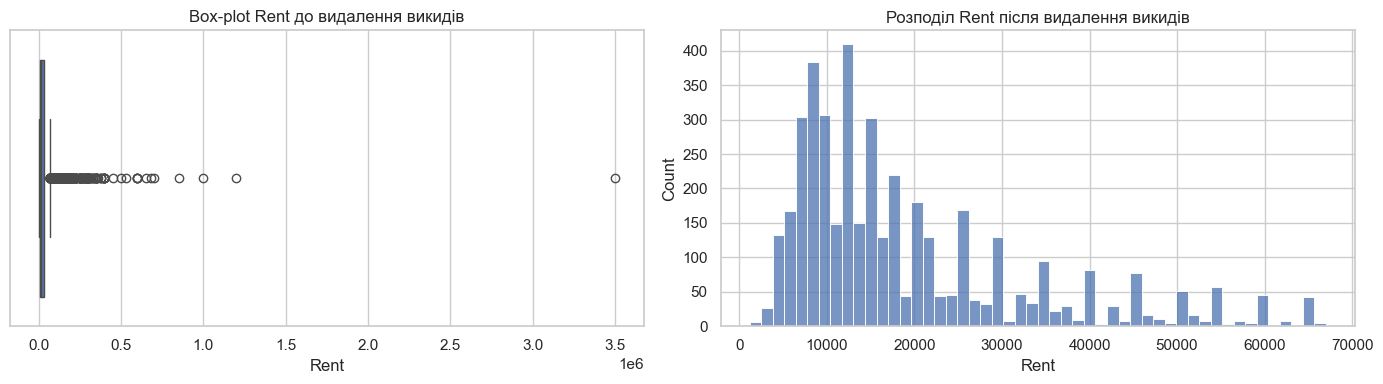

In [7]:
q1 = df['Rent'].quantile(0.25)
q3 = df['Rent'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
is_outlier = (df['Rent'] < lower_bound) | (df['Rent'] > upper_bound)

print(f'Q1 = {q1:,.0f}, Q3 = {q3:,.0f}, IQR = {iqr:,.0f}')
print(f'Межі: від {lower_bound:,.0f} до {upper_bound:,.0f}')
print(f'Викидів: {is_outlier.sum()} ({is_outlier.mean():.1%})')
print('Викиди за містами:', df.loc[is_outlier, 'City'].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df['Rent'], ax=axes[0])
axes[0].set_title('Box-plot Rent до видалення викидів')

df = df[~is_outlier].copy()
print(f'Після видалення викидів лишилось {len(df)} рядків')

sns.histplot(df['Rent'], bins=50, ax=axes[1])
axes[1].set_title('Розподіл Rent після видалення викидів')
plt.tight_layout()
plt.show()

In [8]:
cat_cols = df.select_dtypes('object').columns
display(df[cat_cols].nunique().sort_values().to_frame('Унікальних значень'))

for col in ['City', 'Furnishing Status', 'Area Type', 'Tenant Preferred', 'Point of Contact']:
    print(f'{col}: {df[col].value_counts().to_dict()}')

,Унікальних значень
Area Type,3
Furnishing Status,3
Tenant Preferred,3
Point of Contact,3
City,6
Posted On,80
Floor,340
Area Locality,1997


City: {'Bangalore': 851, 'Chennai': 850, 'Hyderabad': 845, 'Mumbai': 605, 'Delhi': 552, 'Kolkata': 523}
Furnishing Status: {'Semi-Furnished': 1984, 'Unfurnished': 1722, 'Furnished': 520}
Area Type: {'Super Area': 2383, 'Carpet Area': 1841, 'Built Area': 2}
Tenant Preferred: {'Bachelors/Family': 3114, 'Bachelors': 729, 'Family': 383}
Point of Contact: {'Contact Owner': 3168, 'Contact Agent': 1057, 'Contact Builder': 1}


**Висновки до EDA**

1. **Пропусків немає** в жодній колонці.
2. **Статистика.** Медіанна плата — 16 000 рупій, а середня — 34 993. Середнє вдвічі більше за медіану: його тягнуть угору дорогі оголошення (максимум — 3.5 млн). Площа — від 10 до 8 000 кв. футів (10 кв. футів для квартири схоже на помилку в даних). BHK — від 1 до 6, ванних кімнат — від 1 до 10.
3. **Розподіл Rent** сильно скошений вправо (асиметрія ≈ 21). Більшість оголошень коштує до 35 тис., але є довгий хвіст дорогого житла. У логарифмічній шкалі розподіл близький до нормального.
4. **Викиди.** За правилом box-plot верхня межа — 67 500 рупій. Вище неї 520 оголошень (11 %), з них 367 — у Мумбаї. Ми їх видалили, лишилось 4 226 оголошень. Наслідок: модель прогнозує типову оренду до 67.5 тис., а не елітне житло.
5. **Категоріальні змінні.** `City` має 6 значень; `Furnishing Status`, `Area Type`, `Tenant Preferred`, `Point of Contact` — по 3. Їх зручно кодувати One-Hot. Натомість після видалення викидів `Area Locality` має 1 997 значень, `Floor` — 340, `Posted On` — 80. Категорії `Built Area` (2 оголошення) і `Contact Builder` (1) — поодинокі.


## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


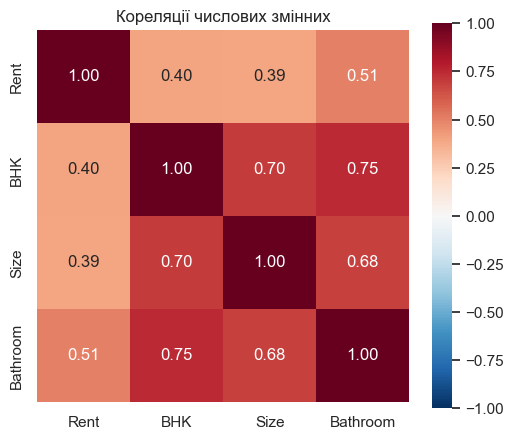

,Rent,BHK,Size,Bathroom
Rent,1.00,0.40,0.39,0.51
BHK,0.40,1.00,0.70,0.75
Size,0.39,0.70,1.00,0.68
Bathroom,0.51,0.75,0.68,1.00


In [9]:
num_cols = ['Rent', 'BHK', 'Size', 'Bathroom']
corr = df[num_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Кореляції числових змінних')
plt.show()

corr.round(2)

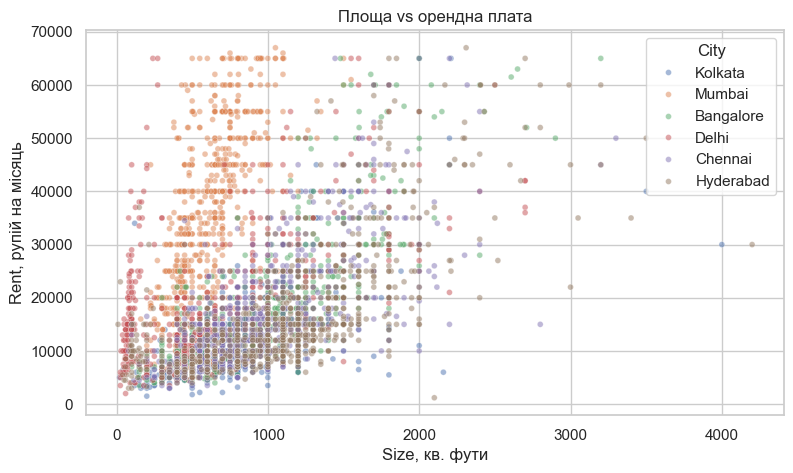

In [10]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Size', y='Rent', hue='City', alpha=0.5, s=18)
plt.title('Площа vs орендна плата')
plt.xlabel('Size, кв. фути')
plt.ylabel('Rent, рупій на місяць')
plt.show()

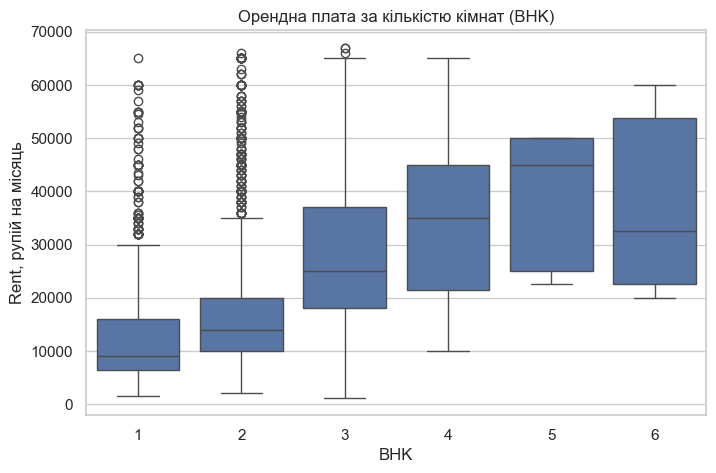

,count,median,mean
BHK,,,
1,1156,9000.0,13413.0
2,2165,14000.0,18141.0
3,838,25000.0,29014.0
4,56,35000.0,35561.0
5,5,45000.0,38500.0
6,6,32500.0,37500.0


In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='BHK', y='Rent')
plt.title('Орендна плата за кількістю кімнат (BHK)')
plt.ylabel('Rent, рупій на місяць')
plt.show()

df.groupby('BHK')['Rent'].agg(['count', 'median', 'mean']).round(0)

**Висновки**

1. З цільовою змінною найсильніше корелює `Bathroom` (0.51), далі `BHK` (0.40) і `Size` (0.39). Звʼязок помірний: жодна ознака сама не пояснює ціну.
2. Ознаки сильно корелюють між собою: `BHK`–`Bathroom` 0.75, `BHK`–`Size` 0.70, `Size`–`Bathroom` 0.68. Це мультиколінеарність. У моделі ці ознаки «ділитимуть» спільний ефект, тому їхні окремі коефіцієнти треба тлумачити обережно.
3. **Size vs Rent.** Плата зростає з площею, але розкид дуже великий. За тієї самої площі житло в Мумбаї значно дорожче, ніж в інших містах. Отже, місто — важлива ознака.
4. **BHK vs Rent.** Медіанна плата зростає з кількістю кімнат: 1 BHK — 9 000, 2 — 14 000, 3 — 25 000, 4 — 35 000, 5 — 45 000. Для 5 і 6 BHK оголошень лише по 5–6, тому їхні медіани ненадійні (для 6 BHK медіана навіть нижча — 32 500). Розкид усередині кожної групи великий і зростає з BHK.

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [12]:
df['Area Type'] = df['Area Type'].replace({'Built Area': 'Super Area'})
df['Point of Contact'] = df['Point of Contact'].replace({'Contact Builder': 'Contact Agent'})

cat_features = ['City', 'Furnishing Status', 'Area Type', 'Tenant Preferred', 'Point of Contact']
df_encoded = pd.get_dummies(df, columns=cat_features, drop_first=True, dtype=int)
dummy_cols = [col for col in df_encoded.columns if col.startswith(tuple(f + '_' for f in cat_features))]
print(f'Нові бінарні колонки ({len(dummy_cols)}):')
print(dummy_cols)

Нові бінарні колонки (11):
['City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Kolkata', 'City_Mumbai', 'Furnishing Status_Semi-Furnished', 'Furnishing Status_Unfurnished', 'Area Type_Super Area', 'Tenant Preferred_Bachelors/Family', 'Tenant Preferred_Family', 'Point of Contact_Contact Owner']


In [13]:
floor_parts = df_encoded['Floor'].str.split(' out of ')
floor_map = {'Ground': 0, 'Upper Basement': -1, 'Lower Basement': -2}

df_encoded['floor_num'] = floor_parts.str[0].map(lambda s: floor_map[s] if s in floor_map else int(s))
df_encoded['total_floors'] = pd.to_numeric(floor_parts.str[1], errors='coerce')
df_encoded['total_floors'] = df_encoded['total_floors'].fillna(df_encoded['floor_num'].clip(lower=1))

display(df_encoded[['Floor', 'floor_num', 'total_floors']].sample(5, random_state=1))
df_encoded[['floor_num', 'total_floors', 'Rent']].corr()['Rent'].round(2).to_frame('Кореляція з Rent')

,Floor,floor_num,total_floors
3954,2 out of 4,2,4.0
2844,1 out of 5,1,5.0
1525,Ground out of 3,0,3.0
439,1 out of 1,1,1.0
3344,4 out of 4,4,4.0


,Кореляція з Rent
floor_num,0.45
total_floors,0.53
Rent,1.00


In [14]:
excluded = ['Posted On', 'Area Locality', 'Floor']
numeric_features = ['BHK', 'Size', 'Bathroom', 'floor_num', 'total_floors']
features = numeric_features + dummy_cols
print('Виключені колонки:', excluded)
print(f'Ознак у моделі: {len(features)}')

X = df_encoded[features].copy()
y = df_encoded['Rent']
print('X:', X.shape, '| y:', y.shape)

Виключені колонки: ['Posted On', 'Area Locality', 'Floor']
Ознак у моделі: 16
X: (4226, 16) | y: (4226,)


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])
X[numeric_features].describe().loc[['mean', 'std']].round(2)

,BHK,Size,Bathroom,floor_num,total_floors
mean,-0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


**Пояснення до feature engineering**

- **One-Hot Encoding** застосували до 5 колонок з 2–6 значеннями: `City`, `Furnishing Status`, `Area Type`, `Tenant Preferred`, `Point of Contact`. `drop_first=True` прибирає одну категорію в кожній колонці. Вона стає базовою, а модель не отримує ідеально залежних колонок. Поодинокі `Built Area` і `Contact Builder` обʼєднали з найближчими категоріями.
- **Нові ознаки:**
  - `floor_num` — поверх квартири (партер = 0, підвал = −1 або −2);
  - `total_floors` — кількість поверхів у будинку. Висотні будинки частіше стоять у дорогих районах великих міст. Кореляція `total_floors` з Rent — 0.53, вища, ніж у `Size` (0.39). У `floor_num` — 0.45.
- **Виключені колонки:**
  - `Area Locality` — 1 997 різних районів. Для One-Hot це забагато: тисячі рідких колонок і ризик перенавчання;
  - `Floor` — текст із 340 значеннями; його зміст тепер у `floor_num` і `total_floors`;
  - `Posted On` — дата публікації оголошення, а не характеристика житла.
- **Стандартизація** зводить числові ознаки до середнього 0 і стандартного відхилення 1. Тоді їхні коефіцієнти можна порівнювати між собою. Для лінійної регресії масштабування не змінює самих прогнозів. Тому стандартизація до поділу на train і test тут не спотворює оцінку якості. У робочому проєкті scaler навчають лише на train.

## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Train: {X_train.shape[0]} оголошень, test: {X_test.shape[0]} оголошень')

model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.Series(model.coef_, index=X.columns).sort_values(key=np.abs, ascending=False)
print(f'Зміщення (intercept): {model.intercept_:,.0f}')
coefficients.round(0).to_frame('Коефіцієнт')

Train: 3380 оголошень, test: 846 оголошень
Зміщення (intercept): 28,052


,Коефіцієнт
City_Mumbai,16353.0
Point of Contact_Contact Owner,-7911.0
Furnishing Status_Unfurnished,-4518.0
Size,3845.0
Furnishing Status_Semi-Furnished,-3449.0
City_Kolkata,-2831.0
BHK,2498.0
City_Hyderabad,-2480.0
Tenant Preferred_Family,-2415.0
City_Delhi,2224.0


In [17]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

pd.DataFrame({
    'Реальна плата': y_test.values[:5],
    'Прогноз': y_test_pred[:5].round(0),
    'Помилка': (y_test.values[:5] - y_test_pred[:5]).round(0),
})

,Реальна плата,Прогноз,Помилка
0,22000,27956.0,-5956.0
1,5000,3072.0,1928.0
2,37000,39460.0,-2460.0
3,8000,2893.0,5107.0
4,15000,15198.0,-198.0


**Які ознаки найбільше впливають на прогноз**

Коефіцієнт показує, на скільки рупій змінюється прогноз:
- для числових ознак — коли ознака зростає на 1 стандартне відхилення;
- для бінарних — коли житло належить до цієї категорії, а не до базової.

Дві найвпливовіші ознаки (за модулем коефіцієнта):
1. **`City_Mumbai` ≈ +16 400.** Житло в Мумбаї дорожче за таке саме житло в Бангалорі (базове місто) приблизно на 16 тис. рупій на місяць.
2. **`Point of Contact_Contact Owner` ≈ −7 900.** Оголошення від власника в середньому дешевші, ніж оголошення через агента. Агенти частіше працюють із дорожчим житлом.

Серед числових ознак найбільше важить `Size` (≈ +3 800 за кожне стандартне відхилення площі), далі `BHK` (≈ +2 500). `Size`, `BHK` і `Bathroom` корелюють між собою, тож модель ділить між ними спільний ефект.

## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R²': r2_score(y_true, y_pred),
    }

metrics = pd.DataFrame({
    'Train': regression_metrics(y_train, y_train_pred),
    'Test': regression_metrics(y_test, y_test_pred),
}).T
print(f'Медіанна плата на тесті: {y_test.median():,.0f}')
metrics.round(3)

Медіанна плата на тесті: 15,000


,MAE,RMSE,R²
Train,5435.095,7574.137,0.700
Test,5380.861,7556.133,0.702


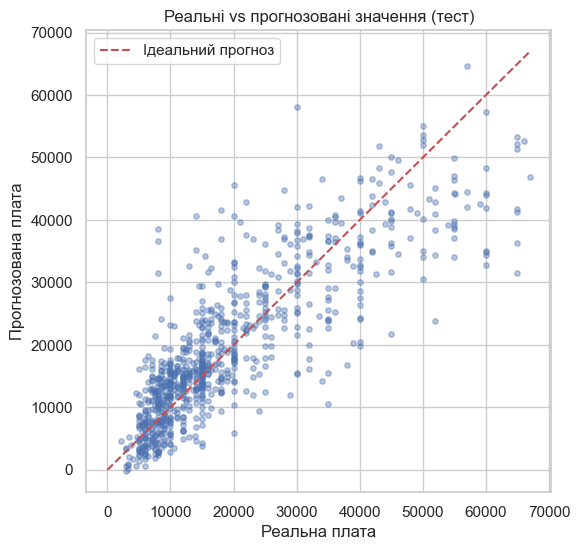

In [19]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_test_pred, alpha=0.4, s=15)
lim = [0, max(y_test.max(), y_test_pred.max())]
plt.plot(lim, lim, 'r--', label='Ідеальний прогноз')
plt.xlabel('Реальна плата')
plt.ylabel('Прогнозована плата')
plt.title('Реальні vs прогнозовані значення (тест)')
plt.legend()
plt.show()

**Висновки**

1. **Метрики.** На тесті MAE ≈ 5 381, RMSE ≈ 7 556, R² ≈ 0.70. Модель пояснює близько 70 % розкиду орендної плати. Середня помилка — приблизно 5.4 тис. рупій за медіанної плати 15 тис. Тобто похибка відчутна: близько третини типової ціни.
2. **Перенавчання немає.** Метрики на train і test майже однакові (R² 0.700 і 0.702).
3. **Недонавчання помірне.** Навіть на train модель пояснює лише 70 % розкиду. Лінійна модель надто проста для нелінійних залежностей. Наприклад, у Мумбаї квадратний фут коштує дорожче, ніж в інших містах, а модель має один коефіцієнт площі для всіх міст.
4. **Графік.** Точки тягнуться вздовж діагоналі, тож загальну тенденцію модель вловлює. Але розкид великий і зростає з ціною. Дороге житло модель часто недооцінює.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

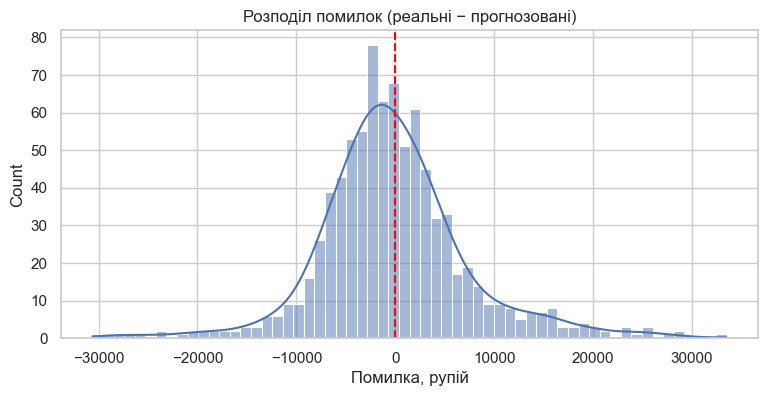

Середня помилка: -179; медіанна: -733; асиметрія: 0.42


In [20]:
residuals = y_test - y_test_pred

plt.figure(figsize=(9, 4))
sns.histplot(residuals, bins=60, kde=True)
plt.axvline(0, color='red', linestyle='--')
plt.title('Розподіл помилок (реальні − прогнозовані)')
plt.xlabel('Помилка, рупій')
plt.show()

print(f'Середня помилка: {residuals.mean():,.0f}; медіанна: {residuals.median():,.0f}; асиметрія: {residuals.skew():.2f}')

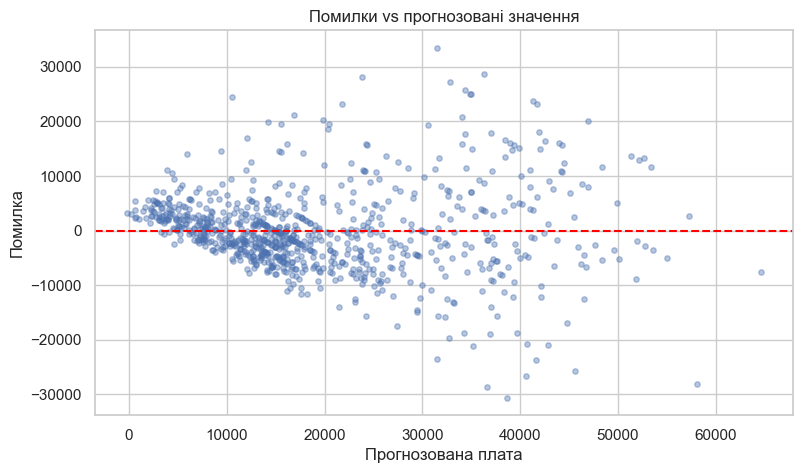

,Середня |помилка|
"(-216.571, 8886.941]",2856.0
"(8886.941, 14151.601]",3472.0
"(14151.601, 18507.878]",4407.0
"(18507.878, 29681.218]",6216.0
"(29681.218, 64623.731]",9968.0


In [21]:
plt.figure(figsize=(9, 5))
plt.scatter(y_test_pred, residuals, alpha=0.4, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Прогнозована плата')
plt.ylabel('Помилка')
plt.title('Помилки vs прогнозовані значення')
plt.show()

pred_groups = pd.qcut(pd.Series(y_test_pred, index=y_test.index), 5)
residuals.abs().groupby(pred_groups, observed=True).mean().round(0).to_frame('Середня |помилка|')

In [22]:
errors_df = df.loc[X_test.index, ['BHK', 'Size', 'Bathroom', 'Floor', 'City', 'Furnishing Status',
                                  'Point of Contact', 'Rent']].copy()
errors_df['Прогноз'] = y_test_pred.round(0)
errors_df['Помилка'] = residuals.round(0)
errors_df['Абс. помилка'] = residuals.abs().round(0)
errors_df.nlargest(5, 'Абс. помилка')

,BHK,Size,Bathroom,Floor,City,Furnishing Status,Point of Contact,Rent,Прогноз,Помилка,Абс. помилка
3962,3,1850,3,5 out of 5,Hyderabad,Furnished,Contact Owner,65000,31511.0,33489.0,33489.0
549,2,650,2,Upper Basement out of 9,Mumbai,Semi-Furnished,Contact Agent,8000,38615.0,-30615.0,30615.0
3520,3,1444,3,11 out of 14,Chennai,Semi-Furnished,Contact Agent,65000,36302.0,28698.0,28698.0
904,2,550,2,3 out of 9,Mumbai,Unfurnished,Contact Agent,8000,36574.0,-28574.0,28574.0
2512,2,1125,2,2 out of 5,Delhi,Furnished,Contact Owner,52000,23848.0,28152.0,28152.0


In [23]:
errors_df['Відносна помилка'] = errors_df['Абс. помилка'] / errors_df['Rent']
aggregations = dict(
    Оголошень=('Rent', 'size'),
    Середня_плата=('Rent', 'mean'),
    MAE=('Абс. помилка', 'mean'),
    MAPE=('Відносна помилка', 'mean'),
)
print('За містами:')
display(errors_df.groupby('City').agg(**aggregations).sort_values('MAE', ascending=False).round(2))
print('За кількістю кімнат:')
display(errors_df.groupby('BHK').agg(**aggregations).round(2))

За містами:


,Оголошень,Середня_плата,MAE,MAPE
City,,,,
Mumbai,118,36140.68,9033.72,0.39
Delhi,115,21742.62,7224.82,0.37
Chennai,143,16161.87,4773.31,0.32
Hyderabad,165,17291.41,4669.45,0.34
Kolkata,131,9810.69,4069.34,0.47
Bangalore,174,16594.36,3846.31,0.25


За кількістю кімнат:


,Оголошень,Середня_плата,MAE,MAPE
BHK,,,,
1,224,12789.96,4356.72,0.42
2,450,17648.10,4868.79,0.33
3,152,30022.05,7682.26,0.30
4,17,33053.00,11794.41,0.45
5,1,50000.00,2777.00,0.06
6,2,60000.00,7186.00,0.12


In [24]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pd.DataFrame({
    'Лінійна регресія, test': regression_metrics(y_test, y_test_pred),
    'Random Forest, train': regression_metrics(y_train, rf.predict(X_train)),
    'Random Forest, test': regression_metrics(y_test, rf.predict(X_test)),
}).T.round(3)

,MAE,RMSE,R²
"Лінійна регресія, test",5380.861,7556.133,0.702
"Random Forest, train",3162.332,4588.105,0.890
"Random Forest, test",4733.399,7011.381,0.744


**Висновки з аналізу помилок**

1. **Розподіл помилок** зосереджений біля нуля (середня ≈ −179), тож систематичного зсуву немає. Розподіл трохи скошений вправо (медіана ≈ −733): великі недооцінки трапляються частіше, ніж великі переоцінки. Хвости довгі — є помилки понад ±30 тис.
2. **Помилка зростає з прогнозом.** Для найдешевших прогнозів середня абсолютна помилка ≈ 2.9 тис., для найдорожчих ≈ 10 тис. На графіку розкид точок розширюється вправо (гетероскедастичність): ціна дорогого житла коливається сильніше.
3. **Найбільші помилки** бувають двох типів:
   - дороге житло, яке модель недооцінює (наприклад, 3 BHK у Хайдарабаді за 65 000 з прогнозом ≈ 31 500);
   - дешеві квартири в Мумбаї (8 000), для яких модель «через місто» прогнозує понад 35 тис. Одна з них — у підвалі (Upper Basement), інша, ймовірно, у віддаленому районі, а район модель не бачить.
4. **Де модель помиляється найбільше:** у **Мумбаї** (MAE ≈ 9 тис.) і **Делі** (≈ 7.2 тис.), а також на житлі з **3–4 BHK**. У відносних величинах найгірше в **Колкаті** (≈ 47 %): там низькі ціни, тож навіть невелика помилка — значна частка ціни.
5. **Наступні кроки для покращення моделі:**
   - додати розташування всередині міста: згрупувати `Area Locality` або закодувати райони середньою ціною (target encoding);
   - додати взаємодії ознак, наприклад `Size × City`, бо ціна квадратного фута в Мумбаї і Колкаті різна; або навчити окремі моделі для міст;
   - прогнозувати `log(Rent)`, щоб зменшити вплив дорогих оголошень і гетероскедастичність;
   - почистити помилки в даних (наприклад, площа 10 кв. футів для 3 BHK);
   - спробувати нелінійні моделі. Ми перевірили Random Forest: на тесті R² зріс з 0.70 до ≈ 0.74, а MAE зменшилась з ≈ 5 400 до ≈ 4 700. Але на train у лісу R² ≈ 0.89 — він частково перенавчається, тож його варто налаштувати.